# Aplicación de _Feature Selection_ en _datasets_ seleccionados

# Aplicación de _Feature Selection_ en _Datasets_ Seleccionados

<div style="text-align: justify;">

En el presente documento se describe la aplicación de _feature selection_ en _datasets_ obtenidos desde el repositorio [BARRA:CuRDa](https://sbcb.inf.ufrgs.br/barracurda), con la finalidad de mitigar el efecto de la **maldición de la dimensionalidad**. Este fenómeno se manifiesta cuando el número de variables $p$ (genes) supera ampliamente al número de observaciones $n$ (muestras experimentales), una situación característica de los datos de expresión génica de alta dimensionalidad (ej.: ~50.000 genes >> 100 muestras). En este contexto, una proporción considerable de los genes medidos puede corresponder a entidades inactivas o biológicamente irrelevantes para la condición o enfermedad bajo estudio, introduciendo ruido estadístico que compromete la validez de los análisis posteriores [^1].

Por lo anterior, se requiere aplicar un _pipeline_ de reducción de dimensionalidad como paso previo a la fase de optimización, con el objetivo de **identificar el subconjunto de genes más informativo** sobre el cual se desarrollarán las etapas subsiguientes de la investigación. La omisión de esta etapa conllevaría consecuencias negativas en múltiples dimensiones: (i) un elevado costo computacional asociado al procesamiento de espacios de alta dimensionalidad; (ii) resultados contaminados por el ruido propio de variables no informativas; y (iii) la obtención de asociaciones biológicas superficiales en términos de la profundidad semántica del grafo acíclico dirigido (DAG) de _Gene Ontology_ (GO) [^1].

En la Tabla 1 se describen los métodos de filtrado estándar que conforman el _pipeline_ de reducción de dimensionalidad propuesto, detallando su fundamento teórico, el criterio de selección empleado y las referencias bibliográficas que los sustentan.

**Tabla 1.** Métodos de _feature selection_ aplicados en el _pipeline_ de preprocesamiento.

|                  Método                  | Descripción |
|:----------------------------------------:|:----------|
| _Near Zero Variance_ [1] [2] [3] | Método de filtrado estadístico que identifica y elimina genes cuya varianza es nula o aproximadamente nula a través del conjunto de muestras. Para ello, evalúa dos criterios simultáneos: la razón de frecuencias entre el valor más prevalente y el segundo más frecuente (_frequency ratio_), y el porcentaje de valores únicos respecto al total de muestras. Los genes que satisfacen ambos umbrales se consideran no informativos y son descartados, dado que su escasa variabilidad no aporta poder discriminativo a los modelos y puede actuar como fuente de ruido en análisis estadísticos posteriores. |
| _Fold-Change_ [4] [5] [8] | Medida de cambio relativo en los niveles de expresión génica entre dos condiciones experimentales, calculada mediante la expresión $\log_2(\bar{X}_{trat}) - \log_2(\bar{X}_{ctrl})$. La escala logarítmica en base 2 otorga simetría a la métrica (valores positivos indican sobreexpresión; negativos, subexpresión) y estabiliza la varianza inherente a los datos de conteo. La selección de genes se realiza aplicando un umbral sobre el valor absoluto del $\log_2$FC, reteniendo únicamente aquellos genes cuya magnitud de cambio supera el criterio establecido. Dado que el _fold-change_ por sí solo no incorpora información sobre la variabilidad interna de los grupos, se recomienda su uso combinado con un estadístico de contraste y corrección por comparaciones múltiples (tasa de falsos descubrimientos, FDR). |
| _Principal Component Analysis_ (PCA) [6] [7] | Técnica de reducción de dimensionalidad no supervisada que, mediante la descomposición espectral de la matriz de covarianza de los datos de expresión, construye un conjunto de combinaciones lineales ortogonales de los genes originales, denominadas componentes principales (PCs), ordenadas de forma decreciente según la proporción de varianza total que explican. A diferencia de los métodos de filtrado anteriores, el PCA opera como un método de _feature extraction_: no selecciona variables originales, sino que genera nuevas representaciones del espacio de datos en dimensionalidad reducida, preservando la mayor parte de la información estadística con un número sustancialmente menor de dimensiones. En el contexto de datos de expresión génica, el PCA se aplica preferentemente sobre datos previamente centrados y escalados (transformación _z-score_), con la finalidad de evitar que genes con alta expresión absoluta dominen los primeros componentes en detrimento de genes biológicamente relevantes pero menos abundantes. |

A continuación, la Tabla 2 expone los _datasets_ seleccionados para la realización de este trabajo de investigación.

[^1]: _La referencia a relaciones superficiales en GO alude a que los términos enriquecidos en análisis funcionales tienden a ubicarse en los niveles más altos (menos específicos) del DAG cuando el conjunto de genes de entrada contiene un elevado número de variables irrelevantes, dificultando la interpretación biológica de los resultados._

</div>

## Referencias

[1] Wang, X., Laird, P. W., Hinoue, T. et al. Non-specific filtering of beta-distributed data. *BMC Bioinformatics*, 15, 199 (2014). https://doi.org/10.1186/1471-2105-15-199

[2] Kuhn, M., & Johnson, K. (2013). *Applied Predictive Modeling*. New York: Springer. http://dx.doi.org/10.1007/978-1-4614-6849-3

[3] Kuhn, M. (2019). Pre-Processing. En *The caret Package*. Recuperado de https://topepo.github.io/caret/pre-processing.html#zero-and-near-zero-variance-predictors

[4] Yang, I. V., Chen, E., Hasseman, J. P. et al. Within the fold: assessing differential expression measures and reproducibility in microarray assays. *Genome Biology*, 3(11), research0062.1–research0062.12 (2002). https://doi.org/10.1186/gb-2002-3-11-research0062

[5] Dalman, M. R., Deeter, A., Nimishakavi, G., & Duan, Z. H. Fold change and p-value cutoffs significantly alter microarray interpretations. *BMC Bioinformatics*, 13(Suppl 2), S11 (2012). https://doi.org/10.1186/1471-2105-13-S2-S11

[6] Ringnér, M. What is principal component analysis? *Nature Biotechnology*, 26, 303–304 (2008). https://doi.org/10.1038/nbt0308-303

[7] Ma, S., & Dai, Y. Principal component analysis based methods in bioinformatics studies. *Briefings in Bioinformatics*, 12(6), 714–722 (2011). https://doi.org/10.1093/bib/bbq090

[8] Love, M.I., Huber, W. & Anders, S. Moderated estimation of fold change and dispersion for RNA-seq data with DESeq2. Genome Biol 15, 550 (2014). https://doi.org/10.1186/s13059-014-0550-8


In [1]:
%%time
############################
# Importaciones
############################
import os                                                   # Llamadas al SO.
from pathlib import Path                                    # Estructura para directorios.
import pandas as pd                                         # Manejo de dataframes.
import numpy as np                                          # Estructuras y operaciones númericas.
import matplotlib.pyplot as plt                             # Creación de gráficos (versión PNG).
import plotly.graph_objects as go                           # Creación de gráficos (versión HTML).
import seaborn as sns                                       # Creación de gráficos en heatmaps.
from sklearn.preprocessing import StandardScaler            # Escalado standar de PCA.
from kneed import KneeLocator                               # Ejecución del método del codo.
from sklearn.decomposition import PCA                       # Aplicación del método de análisis de componentes principales.
from scipy.stats import spearmanr                           # Uso de correlación de spearman.
from scipy.spatial.distance import squareform               # Construcción de matriz para agrupamiento.
from scipy.cluster.hierarchy import linkage, leaves_list    # Agrupamiento jerárquico.
from IPython.display import display                         # Interfaz para mostrar resultados.



############################
# Constantes
############################

# Directorio de archivos de salida.
DATA_DIR =  Path(os.getcwd()).resolve().parent / "Datasets" / "Gene_Expression_source"
OUTPUT_DIR_PREFIX = Path(os.getcwd()).resolve().parent / "Datasets" / "Gene_Expression_reduced"
HEATMAP_DIR = OUTPUT_DIR_PREFIX / "heatmaps_originals"
SPEARMAN_DIR = OUTPUT_DIR_PREFIX / "gene_expresion_matrix"

# Lectura de datasets (en formato zip).
DATASETS = {
    "GSE40419": pd.read_csv(DATA_DIR/"GSE40419.csv.zip"),
    "GSE50760": pd.read_csv(DATA_DIR/"GSE50760.csv.zip"),
    "GSE60052": pd.read_csv(DATA_DIR/"GSE60052.csv.zip"),
    "GSE69240": pd.read_csv(DATA_DIR/"GSE69240.csv.zip"),
    "GSE71651": pd.read_csv(DATA_DIR/"GSE71651.csv.zip")
}


CPU times: total: 15.8 s
Wall time: 16.2 s


In [2]:
# Filas de datos para display final.
filas = []

for nombre, df in DATASETS.items():
    # Separación de columnas de metadata respecto a las de genes.
    cols_meta  = ['ID', 'class']
    cols_genes = [c for c in df.columns if c not in cols_meta]
    df_genes   = df[cols_genes]

    # Balance de clases → string compacto.
    conteos = df['class'].value_counts()
    balance = ' | '.join(f"{cls}: {n}" for cls, n in conteos.items())

    # Detección de tipo de normalización.
    media_global = df_genes.values.mean()
    maximo       = df_genes.values.max()
    pct_enteros  = np.mean(df_genes.values == np.floor(df_genes.values))
    tipo = 'log₂(TPM+1)' if (media_global < 20 and pct_enteros < 0.5) else 'REVISAR'

    # Construcción de fila para tabla final.
    filas.append({
        'Muestras'     : df.shape[0],
        'Genes'        : len(cols_genes),
        'Clases'       : df['class'].nunique(),
        'Balance'      : balance,
        'Nulos'        : int(df.isnull().sum().sum()),
        'Duplicados'   : int(df.duplicated().sum()),
        'Media expr.'  : round(media_global, 3),
        'Máx expr.'    : round(maximo, 3),
        '% enteros'    : round(pct_enteros * 100, 1),
        'Tipo estimado': tipo,
    })

# Dataframe de resumen que será mostrado.
resumen = pd.DataFrame(filas, index=pd.Index(DATASETS.keys(), name='Dataset'))

# Resultado.
display(
    resumen.style
    .background_gradient(subset=['Muestras', 'Genes'], cmap='Blues', axis=0)
    .background_gradient(subset=['Media expr.', 'Máx expr.'], cmap='YlOrRd', axis=0)
    .highlight_between(subset=['Nulos', 'Duplicados'], left=1, right=np.inf, color='#ffcccc')
    .format({
        'Genes'      : '{:,}',
        'Media expr.': '{:.3f}',
        'Máx expr.'  : '{:.3f}',
        '% enteros'  : '{:.1f}%',
    })
    .set_caption('Resumen comparativo de datasets')
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '14px'), ('font-weight', 'bold'), ('margin-bottom', '8px')]},
        {'selector': 'th',
         'props': [('text-align', 'center'), ('background-color', '#1a141d'), ('padding', '6px 10px')]},
        {'selector': 'td',
         'props': [('text-align', 'center'), ('padding', '4px 10px')]},
    ])
)

,Muestras,Genes,Clases,Balance,Nulos,Duplicados,Media expr.,Máx expr.,% enteros,Tipo estimado
Dataset,,,,,,,,,,
GSE40419,164,"58,735",2,Tumor: 87 | Normal: 77,0,0,4.456,21.194,0.0%,log₂(TPM+1)
GSE50760,54,"58,148",3,Primary: 18 | Normal: 18 | Metastasis: 18,0,0,3.843,22.053,0.0%,log₂(TPM+1)
GSE60052,86,"58,735",2,Tumor: 79 | Normal: 7,0,0,4.652,19.348,0.0%,log₂(TPM+1)
GSE69240,35,"58,735",2,Tumor: 25 | Normal: 10,0,0,3.977,23.238,0.0%,log₂(TPM+1)
GSE71651,33,"58,735",2,Normal: 18 | Tumor: 15,0,0,4.302,19.595,0.0%,log₂(TPM+1)


  HTML guardado → C:\Users\benja\Desktop\workspace\Thesis\Datasets\Gene_Expression_reduced\heatmaps_originals\GSE40419_heatmap.html
  HTML guardado → C:\Users\benja\Desktop\workspace\Thesis\Datasets\Gene_Expression_reduced\heatmaps_originals\GSE50760_heatmap.html
  HTML guardado → C:\Users\benja\Desktop\workspace\Thesis\Datasets\Gene_Expression_reduced\heatmaps_originals\GSE60052_heatmap.html
  HTML guardado → C:\Users\benja\Desktop\workspace\Thesis\Datasets\Gene_Expression_reduced\heatmaps_originals\GSE69240_heatmap.html
  HTML guardado → C:\Users\benja\Desktop\workspace\Thesis\Datasets\Gene_Expression_reduced\heatmaps_originals\GSE71651_heatmap.html


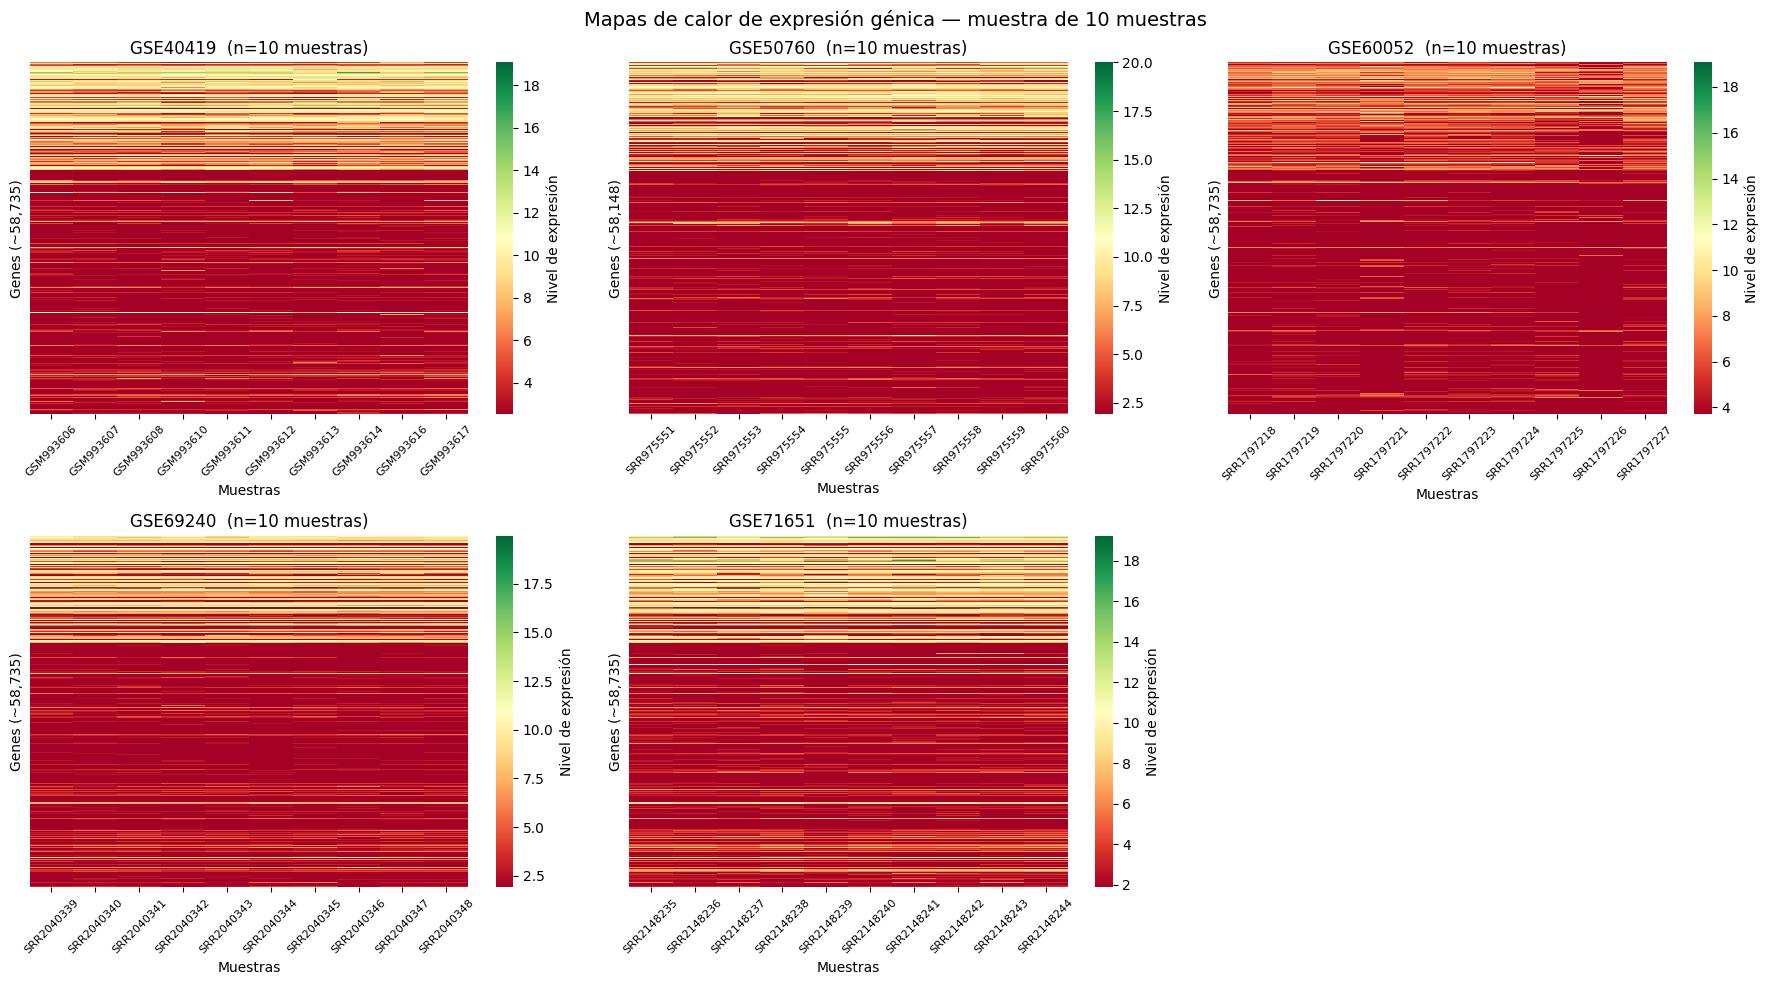


  PNG guardado → C:\Users\benja\Desktop\workspace\Thesis\Datasets\Gene_Expression_reduced\heatmaps_originals\heatmaps_overview.png


In [3]:
# Muestras a mostrar en PNG, se decidió proporcionar los 10 de mayor
# varianza. Considerar que, las versiones HTML muestra el heatmap
# completo
N_SAMPLE = 10

# ─── Marco de figura PNG única con subplots ───────────────────────────
# Es una malla en la cual por fila se presentan 3 datasets.
n_ds   = len(DATASETS)
n_cols = 3
n_rows = (n_ds + n_cols - 1) // n_cols
fig_png, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 6, n_rows * 5))
axes = axes.flatten()

# ─── HTML interactivo (todas las muestras) ───────────────
for ax_idx, (nombre, df) in enumerate(DATASETS.items()):
    # Extracción de filas de metadata y traspocisión para dejar las muestras como eje x
    # y los genes como el eje y.
    cols_genes = [c for c in df.columns if c not in ['ID', 'class']]
    matriz = df[cols_genes].set_index(df['ID']).T

    # Construcción de figura.
    fig_html = go.Figure(data=go.Heatmap(
        z=matriz.values,
        x=list(matriz.columns),
        colorscale='RdYlGn',
        colorbar=dict(title='Nivel de expresión'),
        hoverongaps=False,
        showscale=True,
    ))
    fig_html.update_layout(
        title=f'Mapa de calor interactivo — {nombre}',
        xaxis_title='Muestras',
        yaxis_title=f'Genes (~{len(cols_genes):,})',
        yaxis=dict(showticklabels=False),
        height=650,
        template='plotly_white',
    )
    html_path = HEATMAP_DIR / f"{nombre}_heatmap.html"
    fig_html.write_html(str(html_path))
    print(f"  HTML guardado → {html_path}")

    # ─── PNG: primeras N_SAMPLE muestras ─────────────────────
    sample_cols  = list(matriz.columns[:N_SAMPLE])
    matriz_sample = matriz[sample_cols]

    ax = axes[ax_idx]
    sns.heatmap(
        matriz_sample,
        cmap='RdYlGn',
        xticklabels=True,
        yticklabels=False,
        linewidths=0,
        cbar_kws={'label': 'Nivel de expresión'},
        ax=ax,
    )
    ax.set_xlabel('Muestras')
    ax.set_ylabel(f'Genes (~{len(cols_genes):,})')
    ax.set_title(f'{nombre}  (n={len(sample_cols)} muestras)')
    ax.tick_params(axis='x', rotation=45, labelsize=8)

# Ocultar celdas vacías en la cuadrícula.
for idx in range(n_ds, len(axes)):
    axes[idx].set_visible(False)

fig_png.suptitle('Mapas de calor de expresión génica — muestra de 10 muestras', fontsize=14)
fig_png.tight_layout()
png_path = HEATMAP_DIR / "heatmaps_overview.png"
fig_png.savefig(str(png_path), dpi=150, bbox_inches='tight')
plt.show()
print(f"\n  PNG guardado → {png_path}")


Dataset: GSE40419
  NZV — genes evaluados : 58,735
  NZV — genes eliminados: 23,362  (freq_ratio > 19.0, % únicos < 10.0%)
  NZV — genes retenidos : 35,373


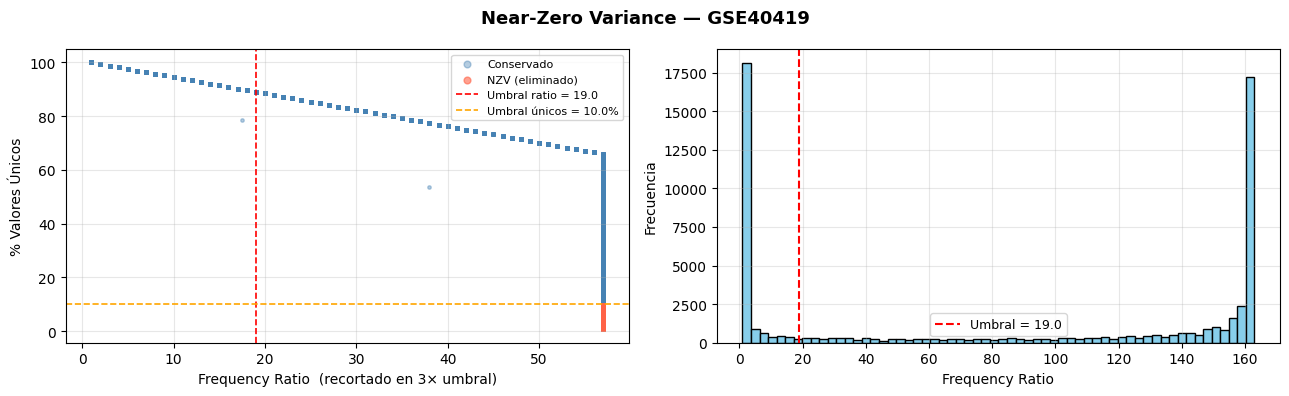


Dataset: GSE50760
  NZV — genes evaluados : 58,148
  NZV — genes eliminados: 27,291  (freq_ratio > 19.0, % únicos < 10.0%)
  NZV — genes retenidos : 30,857


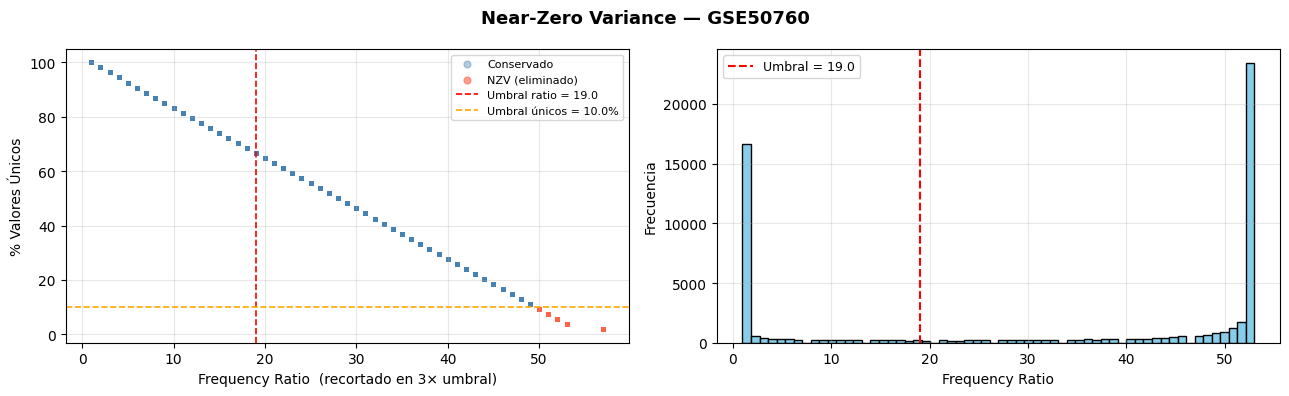


Dataset: GSE60052
  NZV — genes evaluados : 58,735
  NZV — genes eliminados: 16,716  (freq_ratio > 19.0, % únicos < 10.0%)
  NZV — genes retenidos : 42,019


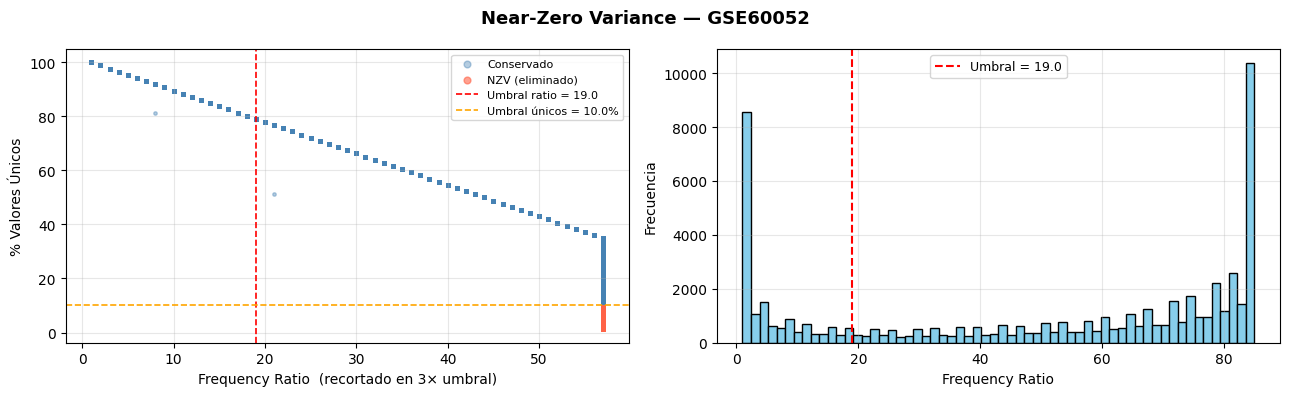


Dataset: GSE69240
  NZV — genes evaluados : 58,735
  NZV — genes eliminados: 18,985  (freq_ratio > 19.0, % únicos < 10.0%)
  NZV — genes retenidos : 39,750


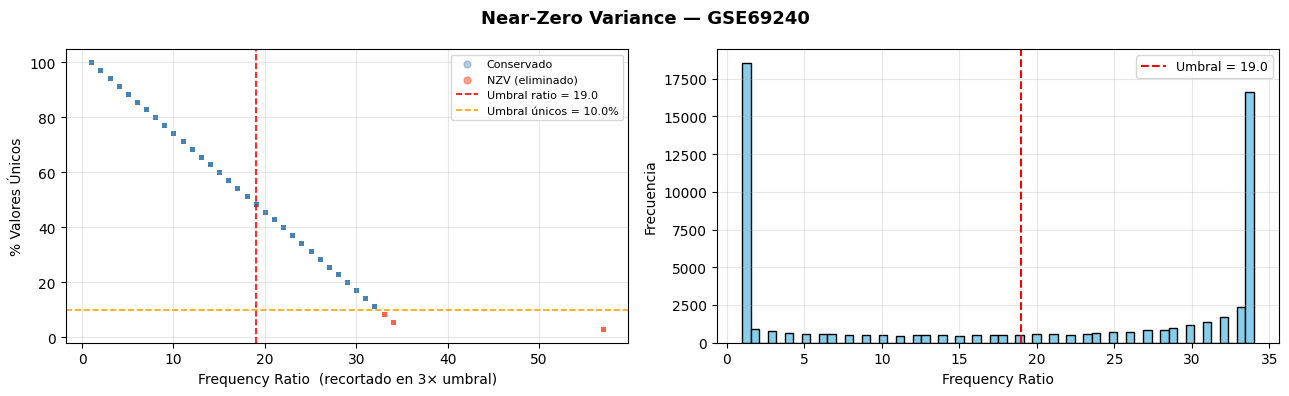


Dataset: GSE71651
  NZV — genes evaluados : 58,735
  NZV — genes eliminados: 18,568  (freq_ratio > 19.0, % únicos < 10.0%)
  NZV — genes retenidos : 40,167


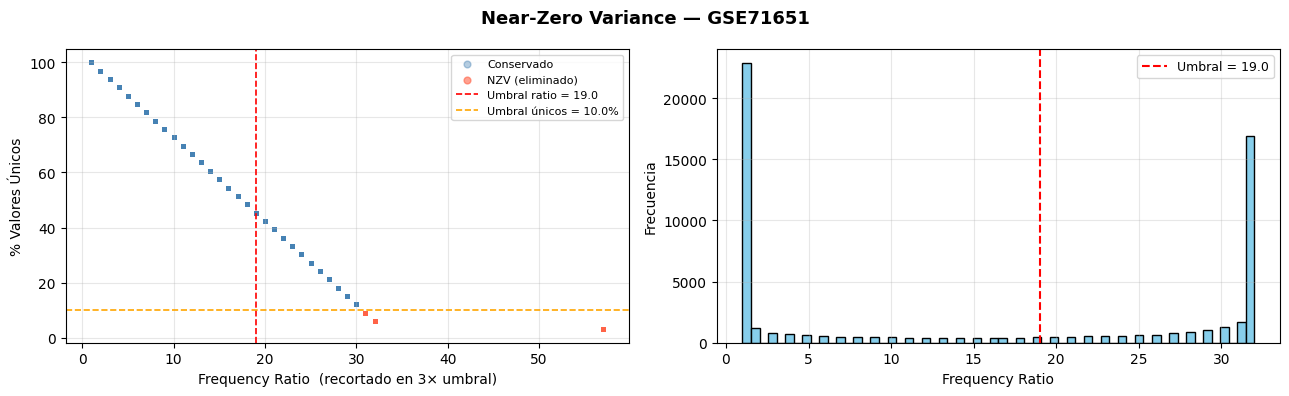

In [4]:
# ============================================================
# PASO 1: Separar metadata y convertir a numpy por dataset
# (Por cada uno -> { nombre: { 'dataX', 'targetY', 'genes', 'ids' })
#   - dataX:   Arreglo de valores de expresión por cada gen.
#   - targetY: Mascara de reconocimiento de muestras por posición.
#   - genes:   Identificadores de genes.
#   - ids:     Identificadores de muestras.
# ============================================================
DATASETS_NUMPY = {}
for nombre, df in DATASETS.items():
    df.columns  = df.columns.str.strip()
    df['ID']    = df['ID'].str.strip()
    df['class'] = df['class'].str.strip()
    cols_genes = [c for c in df.columns if c not in ['ID', 'class']]
    dataX   = df[cols_genes].to_numpy()
    targetY = np.where(df['class'] == 'Normal', 0, 1)
    genes   = np.array(cols_genes)
    ids     = df['ID'].to_numpy()

    DATASETS_NUMPY[nombre] = {
        'dataX'  : dataX,
        'targetY': targetY,
        'genes'  : genes,
        'ids'    : ids
    }

# ============================================================
# PASO 2: Near-Zero Variance — frequency ratio + % valores únicos
# Implementación fiel a nearZeroVar (Kuhn, 2013).
# ============================================================
def near_zero_var(X, 
                  genes,
                  freq_cut=19.0,   # umbral frequency ratio (95/5 ≈ 19)
                  unique_cut=10.0, # umbral % valores únicos
                  verbose=True):
    """
    Detecta genes con varianza casi-cero aplicando los dos criterios de
    nearZeroVar (Kuhn & Johnson, 2013, Applied Predictive Modeling):

      1. Frequency ratio  = freq(valor_más_común) / freq(segundo_más_común)
         → Un ratio alto indica que un valor domina la distribución.
      2. % valores únicos = (n_únicos / n_muestras) × 100
         → Un porcentaje bajo indica poca diversidad de valores.
     

    Un gen se marca como NZV si AMBAS condiciones se superan simultáneamente.

    Parámetros
    ----------
    X           : ndarray de valores de expresión.
    genes       : ndarray de nombres de genes
    freq_cut    : umbral de frequency ratio        (default 19.0 → 95/5)
    unique_cut  : umbral de % de valores únicos    (default 10.0 %)

    Retorna
    -------
    mascara_nzv : ndarray bool, True = gen a CONSERVAR
    metricas    : pd.DataFrame con métricas por gen
    """
    n_muestras, n_genes = X.shape
    resultados = []

    for j in range(n_genes):
        col = X[:, j]

        # --- Conteo de frecuencias ---
        valores, conteos = np.unique(col, return_counts=True)
        idx_ord          = np.argsort(-conteos)          # orden descendente
        conteos_ord      = conteos[idx_ord]
        n_unicos         = len(valores)

        # --- Frequency ratio ---
        if n_unicos == 1:
            freq_ratio = np.inf                          # varianza cero pura
        else:
            freq_ratio = conteos_ord[0] / conteos_ord[1]

        # --- Porcentaje de valores únicos ---
        pct_unicos = (n_unicos / n_muestras) * 100

        # --- Criterio NZV: ambas condiciones deben cumplirse ---
        es_nzv = (freq_ratio > freq_cut) and (pct_unicos < unique_cut)

        # --- Por gen se establece este resumen de estadisticas ---
        resultados.append({
            'gen'        : genes[j],
            'varianza'   : np.var(col),
            'freq_ratio' : round(freq_ratio, 4),
            'pct_unicos' : round(pct_unicos, 4),
            'es_nzv'     : es_nzv
        })

    # Se identifican aquellos genes que deben eliminarse (manteniendo ids).
    metricas    = pd.DataFrame(resultados).set_index('gen')
    mascara_nzv = ~metricas['es_nzv'].values   # True = conservar

    if verbose:
        n_eliminados = (~mascara_nzv).sum()
        print(f"  NZV — genes evaluados : {n_genes:>6,}")
        print(f"  NZV — genes eliminados: {n_eliminados:>6,}  "
              f"(freq_ratio > {freq_cut}, % únicos < {unique_cut}%)")
        print(f"  NZV — genes retenidos : {mascara_nzv.sum():>6,}")

    return mascara_nzv, metricas


# --- Visualización de métricas NZV (scatter + histograma) ---
def plot_nzv(metricas, nombre, freq_cut=19.0, unique_cut=10.0):
    """
    Genera dos gráficos para inspeccionar visualmente el filtro NZV:
      • Scatter: frequency ratio vs % valores únicos, con zonas de corte.
      • Histograma: distribución del frequency ratio (recortado en p99).
    """
    nzv     = metricas[metricas['es_nzv']]
    no_nzv  = metricas[~metricas['es_nzv']]

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    fig.suptitle(f'Near-Zero Variance — {nombre}', fontsize=13, fontweight='bold')

    # ── Scatter: frequency ratio vs % únicos ──────────────────────────────
    ax = axes[0]
    ax.scatter(no_nzv['freq_ratio'].clip(upper=freq_cut * 3),
               no_nzv['pct_unicos'],
               s=6, alpha=0.4, color='steelblue', label='Conservado')
    ax.scatter(nzv['freq_ratio'].clip(upper=freq_cut * 3),
               nzv['pct_unicos'],
               s=6, alpha=0.6, color='tomato', label='NZV (eliminado)')
    ax.axvline(freq_cut,    color='red',    linestyle='--', linewidth=1.2,
               label=f'Umbral ratio = {freq_cut}')
    ax.axhline(unique_cut,  color='orange', linestyle='--', linewidth=1.2,
               label=f'Umbral únicos = {unique_cut}%')
    ax.set_xlabel('Frequency Ratio  (recortado en 3× umbral)')
    ax.set_ylabel('% Valores Únicos')
    ax.legend(fontsize=8, markerscale=2)
    ax.grid(True, alpha=0.3)

    # ── Histograma: frequency ratio ────────────────────────────────────────
    ax2    = axes[1]
    ratio_clip = metricas['freq_ratio'].clip(upper=np.percentile(
                     metricas['freq_ratio'].replace(np.inf, np.nan).dropna(), 99))
    ax2.hist(ratio_clip, bins=60, color='skyblue', edgecolor='black')
    ax2.axvline(freq_cut, color='red', linestyle='--', linewidth=1.5,
                label=f'Umbral = {freq_cut}')
    ax2.set_xlabel('Frequency Ratio')
    ax2.set_ylabel('Frecuencia')
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


# ============================================================
# Aplicar NZV a todos los datasets
# ============================================================
DATASETS_NZV = {}

for nombre, datos in DATASETS_NUMPY.items():
    dataX = datos['dataX']
    genes = datos['genes']

    print(f"\n{'='*50}")
    print(f"Dataset: {nombre}")

    mascara_nzv, metricas = near_zero_var(
        dataX, genes,
        freq_cut   = 19.0,   # 95/5 — umbral estándar Kuhn (2013)
        unique_cut = 10.0,   # < 10% valores únicos
        verbose    = True
    )

    plot_nzv(metricas, nombre, freq_cut=19.0, unique_cut=10.0)

    dataX_nzv = dataX[:, mascara_nzv]
    genes_nzv = genes[mascara_nzv]

    DATASETS_NZV[nombre] = {
        **datos,
        'dataX'      : dataX_nzv,
        'genes'      : genes_nzv,
        'mascara_nzv': mascara_nzv,
        'metricas_nzv': metricas
    }


Dataset : GSE40419


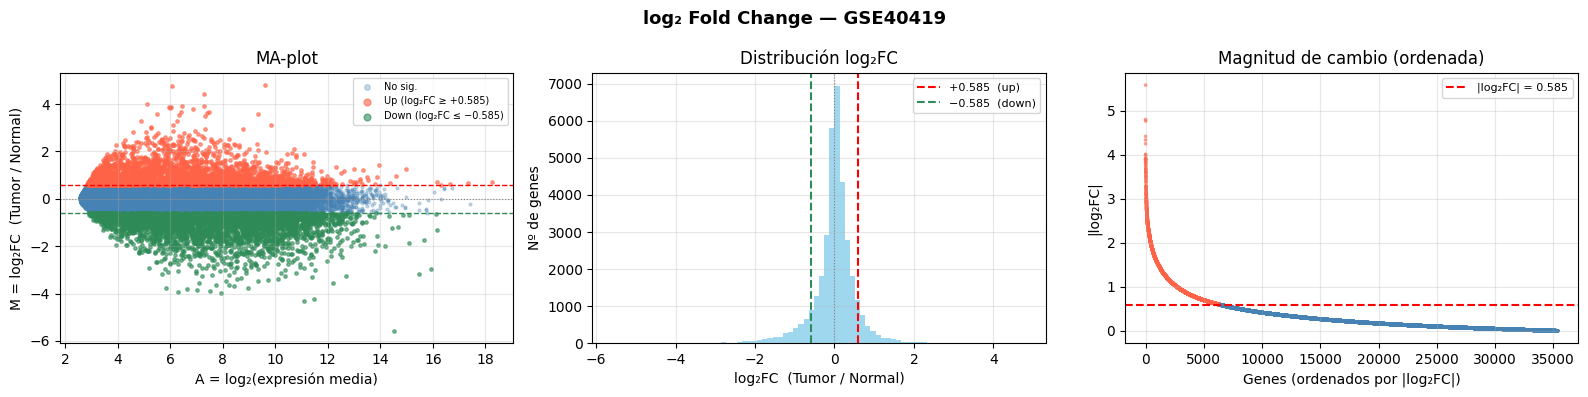

  Genes entrada      : 35,373
  Genes retenidos    :  6,498  (|log₂FC| ≥ 0.585)
    ↑ Up-regulated   :  2,993  (log₂FC ≥ +0.585)
    ↓ Down-regulated :  3,505  (log₂FC ≤ −0.585)
  log₂FC rango       : [-5.577,  4.798]

Dataset : GSE50760


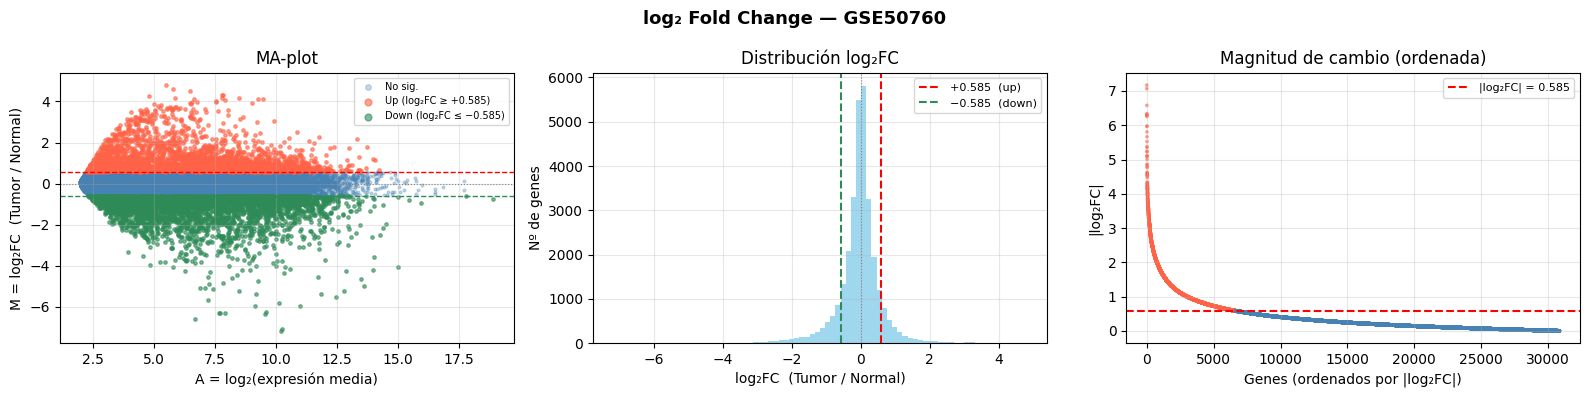

  Genes entrada      : 30,857
  Genes retenidos    :  6,650  (|log₂FC| ≥ 0.585)
    ↑ Up-regulated   :  2,962  (log₂FC ≥ +0.585)
    ↓ Down-regulated :  3,688  (log₂FC ≤ −0.585)
  log₂FC rango       : [-7.170,  4.797]

Dataset : GSE60052


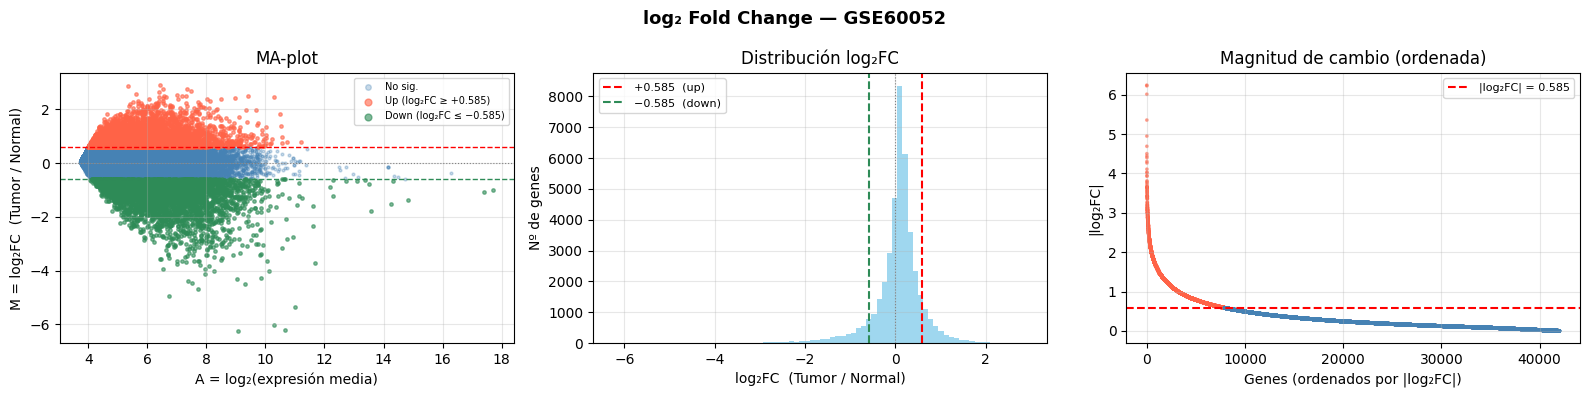

  Genes entrada      : 42,019
  Genes retenidos    :  7,935  (|log₂FC| ≥ 0.585)
    ↑ Up-regulated   :  4,257  (log₂FC ≥ +0.585)
    ↓ Down-regulated :  3,678  (log₂FC ≤ −0.585)
  log₂FC rango       : [-6.241,  2.899]

Dataset : GSE69240


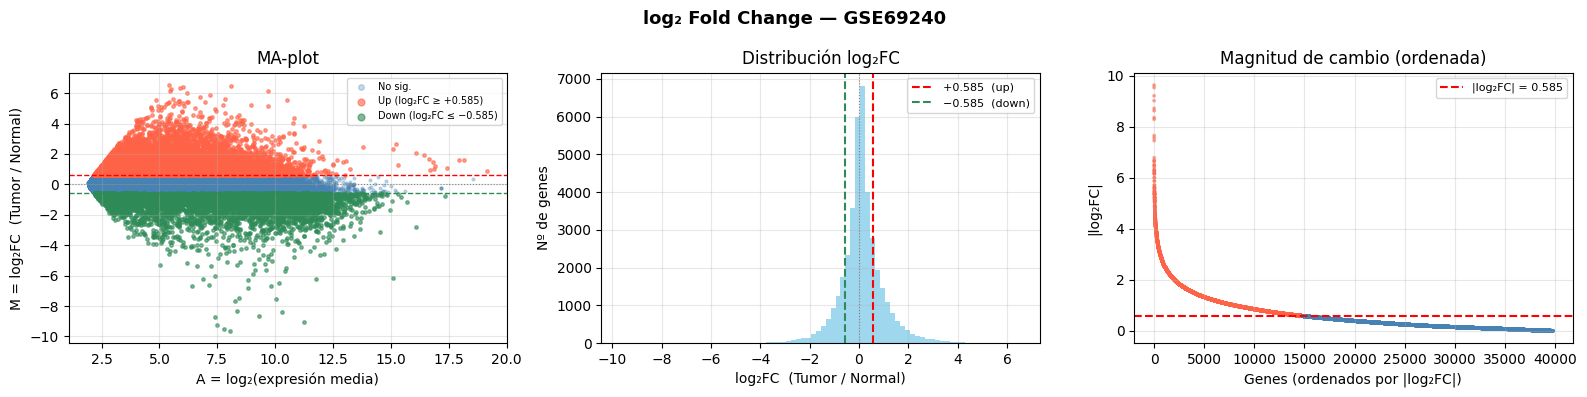

  Genes entrada      : 39,750
  Genes retenidos    : 14,808  (|log₂FC| ≥ 0.585)
    ↑ Up-regulated   :  8,839  (log₂FC ≥ +0.585)
    ↓ Down-regulated :  5,969  (log₂FC ≤ −0.585)
  log₂FC rango       : [-9.639,  6.523]

Dataset : GSE71651


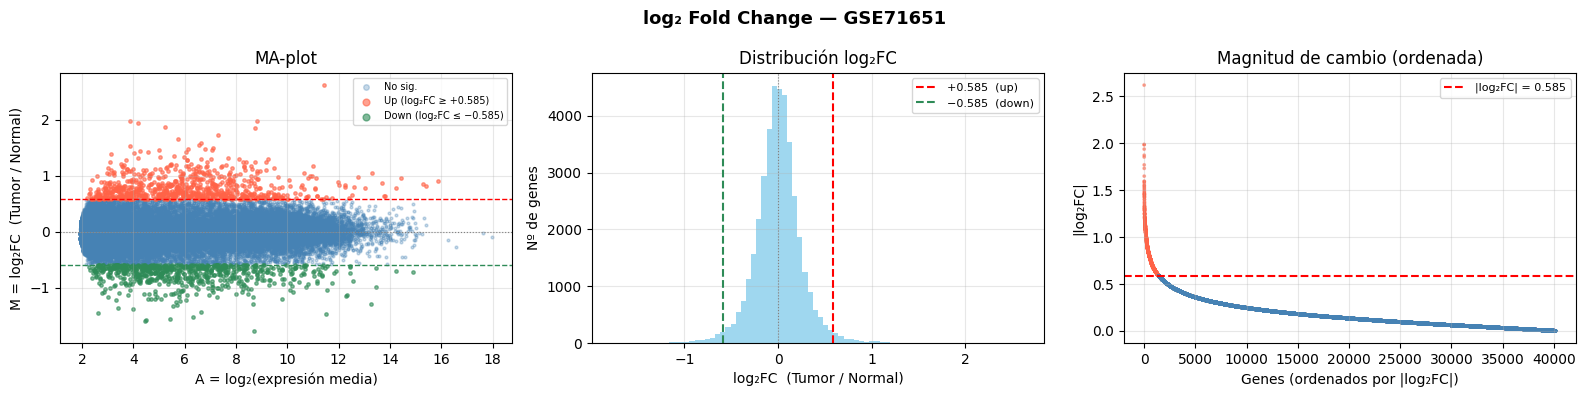

  Genes entrada      : 40,167
  Genes retenidos    :  1,444  (|log₂FC| ≥ 0.585)
    ↑ Up-regulated   :    770  (log₂FC ≥ +0.585)
    ↓ Down-regulated :    674  (log₂FC ≤ −0.585)
  log₂FC rango       : [-1.770,  2.620]


In [5]:
# ============================================================
# PASO 1: Calcular log₂ Fold Change para cada dataset utilizando
# los valores por defecto del datasets (no requieren normalización).
#           log₂FC = media_tumor − media_normal
#
# Ventajas respecto a FC lineal (Quackenbush, 2002):
#  • Simetría: +1 = doble expresión, −1 = mitad
#  • Estabilización de varianza en datos de conteo
#  • Permite umbral bidireccional simple: |log₂FC| ≥ umbral
#
# Entrada : DATASETS_NZV  (genes ya filtrados por NZV)
# Salida  : DATASETS_FC
# ============================================================
def calcular_log2fc(dataX, targetY):
    """
    Calcula el log₂ Fold Change (Tumor vs Normal) por gen.

    Fórmula:
        log₂FC_j = μ_tumor_j − μ_normal_j

    Parámetros
    ----------
    dataX   : valores de expresión asociados a cada gen.
    targetY : Mascara de reconocimiento de muestras.

    Retorna
    -------
    log2fc       : ndarray (n_genes,)
    media_normal : ndarray (n_genes,)
    media_tumor  : ndarray (n_genes,)
    """
    data_normal  = dataX[targetY == 0, :]       # Normal.
    data_tumor   = dataX[targetY == 1, :]       # Tumoral.

    media_normal = np.mean(data_normal, axis=0)
    media_tumor  = np.mean(data_tumor,  axis=0)

    # log₂FC = log₂(tumor) − log₂(normal) -> Fórmula original.
    log2fc = media_tumor - media_normal

    # Sanidad: reemplazar NaN/±Inf residuales (en caso de ocurir).
    n_invalidos = np.sum(~np.isfinite(log2fc))
    if n_invalidos > 0:
        print(f"{n_invalidos:,} genes con log₂FC inválido → reemplazados por 0")
        log2fc = np.nan_to_num(log2fc, nan=0.0, posinf=0.0, neginf=0.0)

    return log2fc, media_normal, media_tumor


def plot_log2fc(log2fc, media_normal, media_tumor, genes, nombre,
                umbral_fc=1.0):
    """
    Genera tres gráficos complementarios para inspeccionar el log₂FC:

      1. MA-plot:    log₂(expresión media) vs log₂FC — estándar en microarray/RNA-seq.
                     Permite detectar sesgos intensidad-dependientes.
      2. Histograma: Distribución del log₂FC con zonas de corte marcadas.
      3. Lineal:     Genes ordenados por magnitud absoluta de log₂FC.
    """
    # Expresión media global (eje A del MA-plot).
    media_global = (media_normal + media_tumor) / 2
    
    mascara_up   = log2fc >=  umbral_fc
    mascara_down = log2fc <= -umbral_fc
    mascara_ns   = ~(mascara_up | mascara_down)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    fig.suptitle(f'log₂ Fold Change — {nombre}', fontsize=13, fontweight='bold')

    # ── 1. MA-plot ─────────────────────────────────────────────────────────
    ax = axes[0]
    ax.scatter(media_global[mascara_ns],  log2fc[mascara_ns],
               s=4, alpha=0.3, color='steelblue', label='No sig.')
    ax.scatter(media_global[mascara_up],  log2fc[mascara_up],
               s=6, alpha=0.6, color='tomato',    label=f'Up (log₂FC ≥ +{umbral_fc})')
    ax.scatter(media_global[mascara_down], log2fc[mascara_down],
               s=6, alpha=0.6, color='seagreen',  label=f'Down (log₂FC ≤ −{umbral_fc})')
    ax.axhline( umbral_fc, color='red',      linestyle='--', linewidth=1.0)
    ax.axhline(-umbral_fc, color='seagreen', linestyle='--', linewidth=1.0)
    ax.axhline(0,          color='gray',     linestyle=':',  linewidth=0.8)
    ax.set_xlabel('A = log₂(expresión media)')
    ax.set_ylabel('M = log₂FC  (Tumor / Normal)')
    ax.set_title('MA-plot')
    ax.legend(fontsize=7, markerscale=2)
    ax.grid(True, alpha=0.3)

    # ── 2. Histograma de log₂FC ────────────────────────────────────────────
    ax2 = axes[1]
    ax2.hist(log2fc, bins=80, color='skyblue', edgecolor='none', alpha=0.8)
    ax2.axvline( umbral_fc, color='red',      linestyle='--', linewidth=1.5,
                 label=f'+{umbral_fc}  (up)')
    ax2.axvline(-umbral_fc, color='seagreen', linestyle='--', linewidth=1.5,
                 label=f'−{umbral_fc}  (down)')
    ax2.axvline(0,          color='gray',     linestyle=':',  linewidth=0.8)
    ax2.set_xlabel('log₂FC  (Tumor / Normal)')
    ax2.set_ylabel('Nº de genes')
    ax2.set_title('Distribución log₂FC')
    ax2.legend(fontsize=8)
    ax2.grid(True, alpha=0.3)

    # ── 3. Gráfico de magnitud (|log₂FC| ordenado) ────────────────────────
    abs_fc = np.abs(log2fc)
    orden  = np.argsort(abs_fc)[::-1]
    colores = np.where(abs_fc[orden] >= umbral_fc, 'tomato', 'steelblue')

    ax3 = axes[2]
    ax3.scatter(np.arange(len(log2fc)), abs_fc[orden],
                c=colores, s=3, alpha=0.5)
    ax3.axhline(umbral_fc, color='red', linestyle='--', linewidth=1.5,
                label=f'|log₂FC| = {umbral_fc}')
    ax3.set_xlabel('Genes (ordenados por |log₂FC|)')
    ax3.set_ylabel('|log₂FC|')
    ax3.set_title('Magnitud de cambio (ordenada)')
    ax3.legend(fontsize=8)
    ax3.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


# ============================================================
# Aplicar log₂FC a todos los datasets
# ============================================================
DATASETS_FC = {}

# Umbral estándar: |log₂FC| ≥ 1  ↔  cambio ≥ 2× en escala lineal
# Ajustar a 0.585 (1.5×) para criterio más permisivo.
UMBRAL_LOG2FC = 0.585

for nombre, datos in DATASETS_NZV.items():          # ← entrada: post-NZV
    dataX  = datos['dataX']
    targetY = datos['targetY']
    genes  = datos['genes']

    print(f"\n{'='*55}")
    print(f"Dataset : {nombre}")

    log2fc, media_normal, media_tumor = calcular_log2fc(dataX, targetY)

    plot_log2fc(log2fc, media_normal, media_tumor, genes,
                nombre, umbral_fc=UMBRAL_LOG2FC)

    # ── Filtro bidireccional: genes con cambio relevante en CUALQUIER dirección
    mascara_fc = np.abs(log2fc) >= UMBRAL_LOG2FC
    dataX_fc   = dataX[:, mascara_fc]
    genes_fc   = genes[mascara_fc]

    n_up   = np.sum(log2fc[mascara_fc] > 0)
    n_down = np.sum(log2fc[mascara_fc] < 0)

    print(f"  Genes entrada      : {dataX.shape[1]:>6,}")
    print(f"  Genes retenidos    : {dataX_fc.shape[1]:>6,}  (|log₂FC| ≥ {UMBRAL_LOG2FC})")
    print(f"    ↑ Up-regulated   : {n_up:>6,}  (log₂FC ≥ +{UMBRAL_LOG2FC})")
    print(f"    ↓ Down-regulated : {n_down:>6,}  (log₂FC ≤ −{UMBRAL_LOG2FC})")
    print(f"  log₂FC rango       : [{log2fc.min():.3f},  {log2fc.max():.3f}]")

    DATASETS_FC[nombre] = {
        **datos,
        'dataX'       : dataX_fc,
        'genes'       : genes_fc,
        'log2fc'      : log2fc,       # vector completo (pre-filtro) para trazabilidad
        'mascara_fc'  : mascara_fc,
        'media_normal': media_normal,
        'media_tumor' : media_tumor,
    }


Dataset : GSE40419


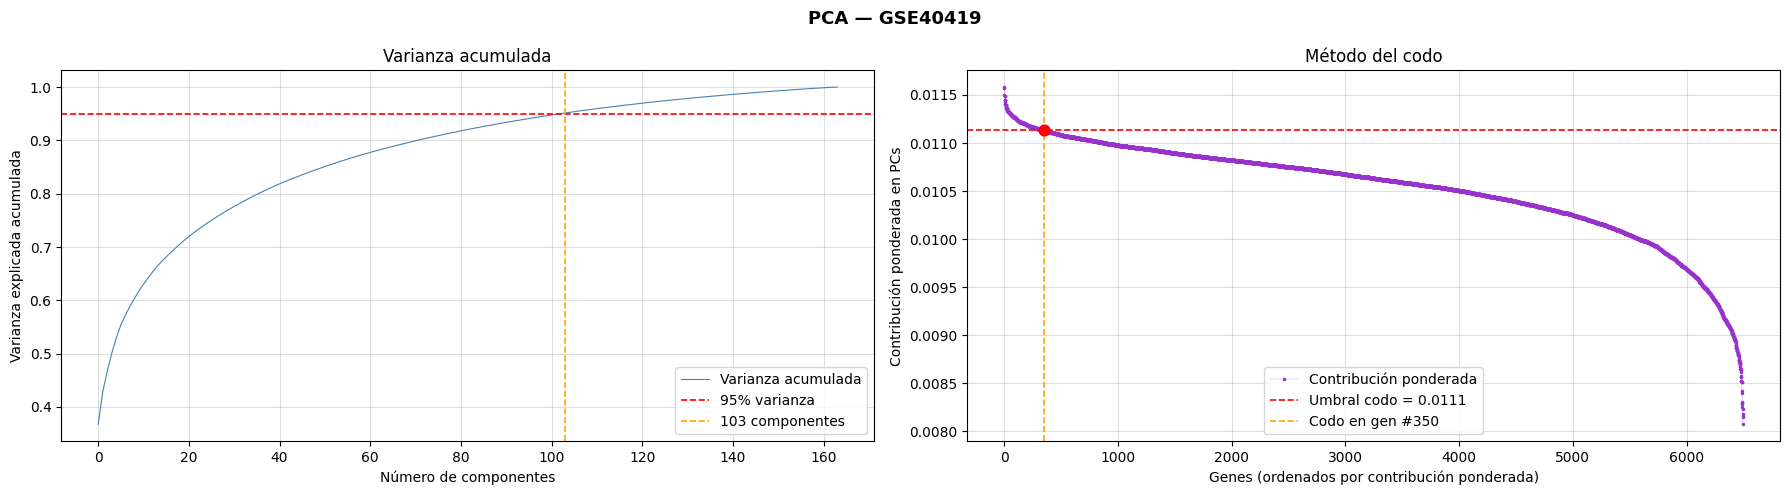

  PCs para 95% varianza   : 103
  Umbral detectado (codo) : 0.0111
  Genes entrada           :  6,498
  Genes retenidos         :    351  (5.4%)

Dataset : GSE50760


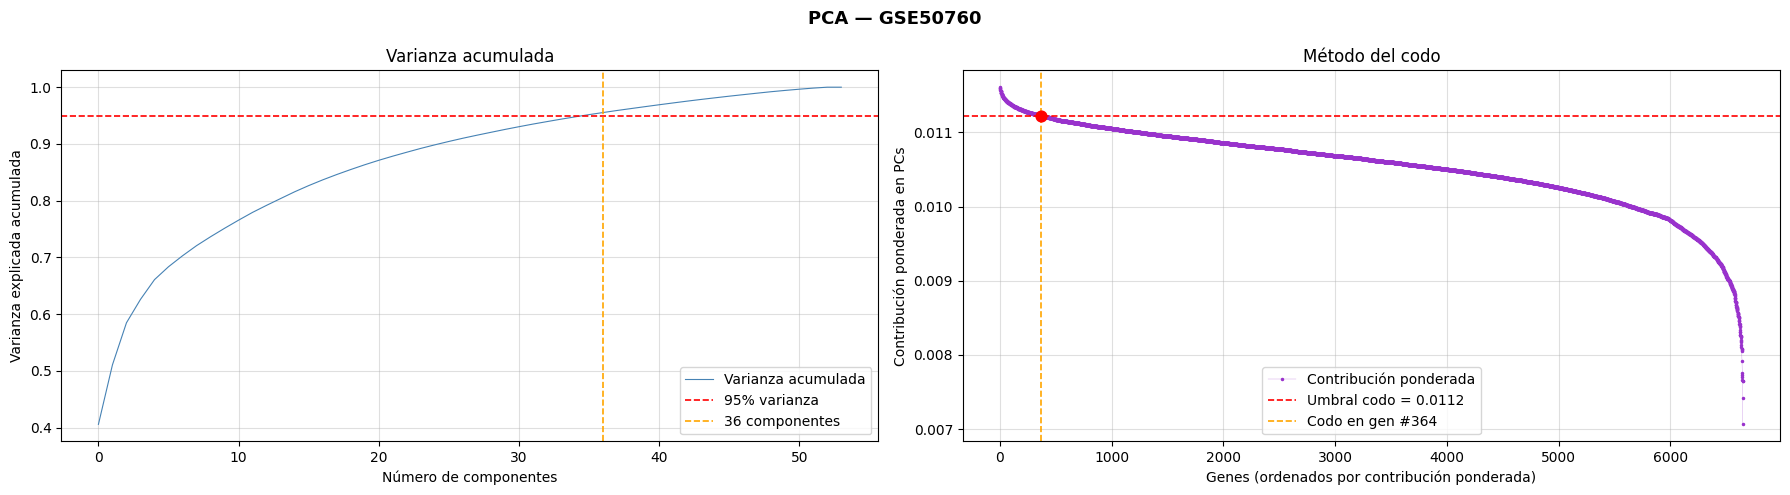

  PCs para 95% varianza   : 36
  Umbral detectado (codo) : 0.0112
  Genes entrada           :  6,650
  Genes retenidos         :    365  (5.5%)

Dataset : GSE60052


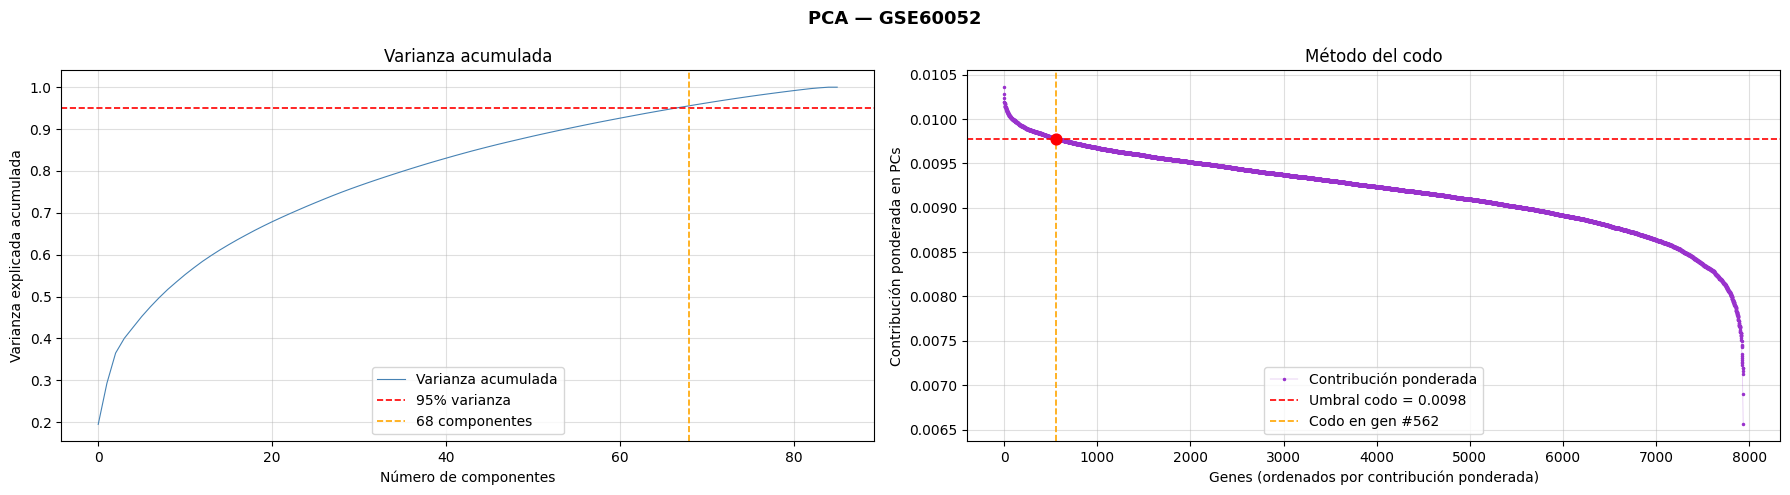

  PCs para 95% varianza   : 68
  Umbral detectado (codo) : 0.0098
  Genes entrada           :  7,935
  Genes retenidos         :    563  (7.1%)

Dataset : GSE69240


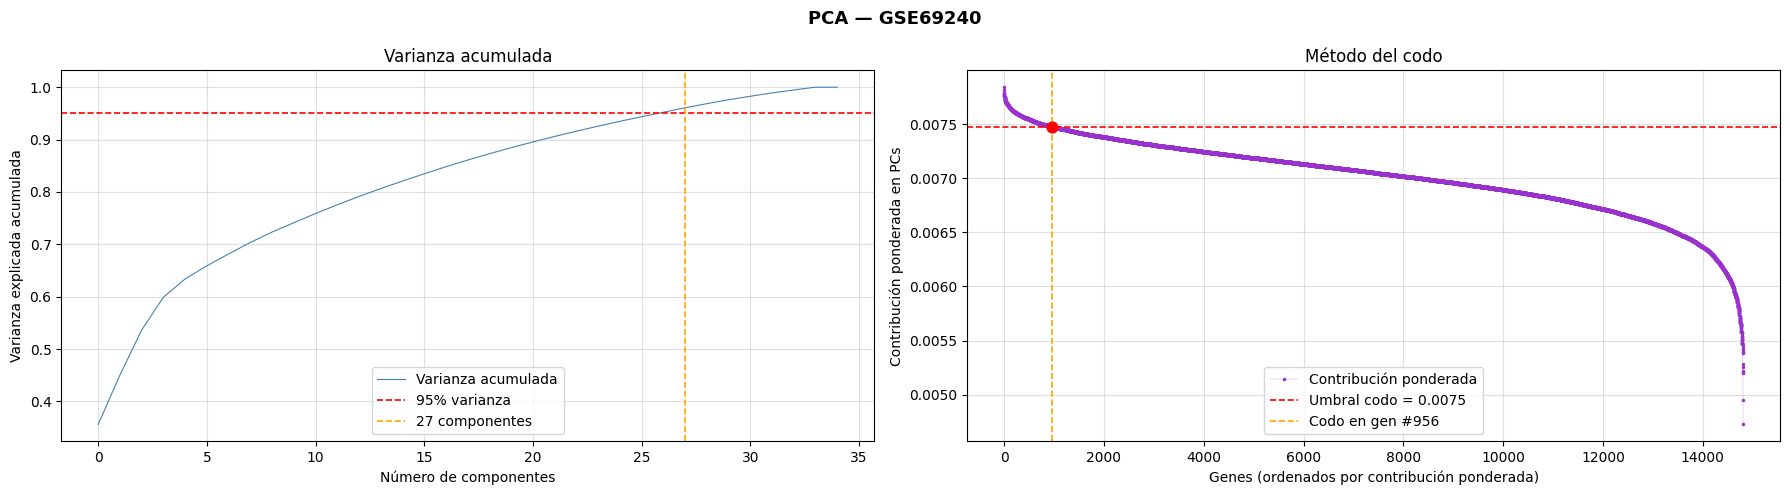

  PCs para 95% varianza   : 27
  Umbral detectado (codo) : 0.0075
  Genes entrada           : 14,808
  Genes retenidos         :    957  (6.5%)

Dataset : GSE71651


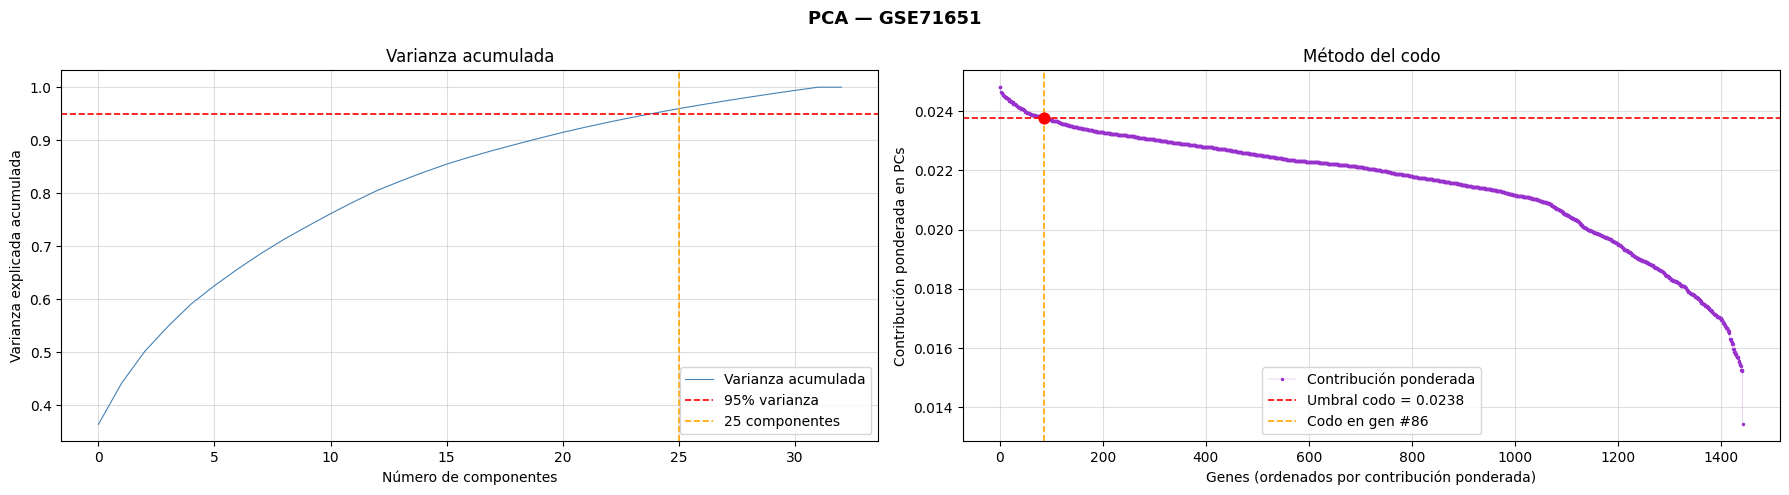

  PCs para 95% varianza   : 25
  Umbral detectado (codo) : 0.0238
  Genes entrada           :  1,444
  Genes retenidos         :     87  (6.0%)

  RESUMEN PIPELINE: NZV → FC → PCA (codo)

GSE40419
  Original  : 58,735 genes
  Post-NZV  : 35,373 genes  (60.2%)
  Post-FC   :  6,498 genes  (11.1%)
  Post-PCA  :    351 genes  (0.6%)  umbral = 0.0111

GSE50760
  Original  : 58,148 genes
  Post-NZV  : 30,857 genes  (53.1%)
  Post-FC   :  6,650 genes  (11.4%)
  Post-PCA  :    365 genes  (0.6%)  umbral = 0.0112

GSE60052
  Original  : 58,735 genes
  Post-NZV  : 42,019 genes  (71.5%)
  Post-FC   :  7,935 genes  (13.5%)
  Post-PCA  :    563 genes  (1.0%)  umbral = 0.0098

GSE69240
  Original  : 58,735 genes
  Post-NZV  : 39,750 genes  (67.7%)
  Post-FC   : 14,808 genes  (25.2%)
  Post-PCA  :    957 genes  (1.6%)  umbral = 0.0075

GSE71651
  Original  : 58,735 genes
  Post-NZV  : 40,167 genes  (68.4%)
  Post-FC   :  1,444 genes  (2.5%)
  Post-PCA  :     87 genes  (0.1%)  umbral = 0.0238


In [6]:
DATASETS_PCA = {}

for nombre, datos in DATASETS_FC.items():
    dataX  = datos['dataX']
    genes  = datos['genes']

    print(f"\n{'='*55}")
    print(f"Dataset : {nombre}")

    # --------------------------------------------------------
    # PASO 1: Centrado y escalado (z-score por gen)
    # --------------------------------------------------------
    scaler    = StandardScaler()
    dataX_std = scaler.fit_transform(dataX)

    # --------------------------------------------------------
    # PASO 2: Ajustar PCA completo
    # --------------------------------------------------------
    n_max    = min(dataX_std.shape[0], dataX_std.shape[1])
    pca      = PCA(n_components=n_max)
    data_pca = pca.fit_transform(dataX_std)

    # --------------------------------------------------------
    # PASO 3: Varianza acumulada
    # --------------------------------------------------------
    varianza_acum = np.cumsum(pca.explained_variance_ratio_)
    n_comp_95     = np.searchsorted(varianza_acum, 0.95) + 1

    # --------------------------------------------------------
    # PASO 4: Contribución ponderada por gen
    # --------------------------------------------------------
    pesos            = pca.explained_variance_ratio_
    contribucion_gen = np.sum(
        np.abs(pca.components_) * pesos[:, np.newaxis],
        axis=0
    )

    contrib_ordenada = np.sort(contribucion_gen)[::-1]
    x_idx            = np.arange(len(contrib_ordenada))

    # --------------------------------------------------------
    # PASO 5: Detección de codo
    # --------------------------------------------------------
    kneedle  = KneeLocator(
        x_idx, contrib_ordenada,
        curve='convex', direction='decreasing',
        interp_method='polynomial'
    )
    idx_codo       = kneedle.knee if kneedle.knee is not None else len(x_idx) // 2
    umbral_contrib = float(contrib_ordenada[idx_codo])

    # --------------------------------------------------------
    # PASO 6: Visualización — ambos gráficos uno al lado del otro
    # --------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(18, 5))
    fig.suptitle(f'PCA — {nombre}', fontsize=13, fontweight='bold')

    # ── Panel izquierdo: varianza acumulada ──────────────────
    ax1 = axes[0]
    ax1.plot(varianza_acum, linewidth=0.8, color='steelblue',
             label='Varianza acumulada')
    ax1.axhline(y=0.95,      color='red',    linestyle='--',
                linewidth=1.2, label='95% varianza')
    ax1.axvline(x=n_comp_95, color='orange', linestyle='--',
                linewidth=1.2, label=f'{n_comp_95} componentes')
    ax1.set_xlabel('Número de componentes')
    ax1.set_ylabel('Varianza explicada acumulada')
    ax1.set_title('Varianza acumulada')
    ax1.legend()
    ax1.grid(True, alpha=0.4)

    # ── Panel derecho: contribución ponderada + codo ─────────
    ax2 = axes[1]
    ax2.plot(contrib_ordenada, marker='o', markersize=1.5,
             linewidth=0.15, color='darkorchid',
             label='Contribución ponderada')
    ax2.axhline(y=umbral_contrib, color='red',    linestyle='--',
                linewidth=1.2,
                label=f'Umbral codo = {umbral_contrib:.4f}')
    ax2.axvline(x=idx_codo,       color='orange', linestyle='--',
                linewidth=1.2,
                label=f'Codo en gen #{idx_codo:,}')
    ax2.scatter(idx_codo, umbral_contrib, color='red', zorder=5, s=60)
    ax2.set_xlabel('Genes (ordenados por contribución ponderada)')
    ax2.set_ylabel('Contribución ponderada en PCs')
    ax2.set_title('Método del codo')
    ax2.legend()
    ax2.grid(True, alpha=0.4)

    plt.tight_layout()
    plt.show()

    print(f"  PCs para 95% varianza   : {n_comp_95}")
    print(f"  Umbral detectado (codo) : {umbral_contrib:.4f}")

    # --------------------------------------------------------
    # PASO 7: Filtrar genes sobre el umbral
    # --------------------------------------------------------
    mascara_pca = contribucion_gen >= umbral_contrib
    dataX_pca   = dataX[:, mascara_pca]
    genes_pca   = genes[mascara_pca]

    print(f"  Genes entrada           : {dataX.shape[1]:>6,}")
    print(f"  Genes retenidos         : {dataX_pca.shape[1]:>6,}  "
          f"({dataX_pca.shape[1]/dataX.shape[1]*100:.1f}%)")

    DATASETS_PCA[nombre] = {
        **datos,
        'dataX'          : dataX_pca,
        'genes'          : genes_pca,
        'pca'            : pca,
        'data_pca'       : data_pca,
        'contribucion'   : contribucion_gen,
        'mascara_pca'    : mascara_pca,
        'umbral_contrib' : umbral_contrib,
        'idx_codo'       : idx_codo,
        'n_comp_95'      : n_comp_95,
        'scaler'         : scaler
    }

# ============================================================
# RESUMEN FINAL — pipeline NZV → FC → PCA
# ============================================================
separador = '=' * 55
print(f"\n{separador}")
print("  RESUMEN PIPELINE: NZV → FC → PCA (codo)")
print(separador)

for nombre in DATASETS_NUMPY:
    n0 = DATASETS_NUMPY[nombre]['dataX'].shape[1]
    n1 = DATASETS_NZV[nombre]['dataX'].shape[1]
    n2 = DATASETS_FC[nombre]['dataX'].shape[1]
    n3 = DATASETS_PCA[nombre]['dataX'].shape[1]
    u  = DATASETS_PCA[nombre]['umbral_contrib']

    print(f"\n{nombre}")
    print(f"  Original  : {n0:>6,} genes")
    print(f"  Post-NZV  : {n1:>6,} genes  ({n1/n0*100:.1f}%)")
    print(f"  Post-FC   : {n2:>6,} genes  ({n2/n0*100:.1f}%)")
    print(f"  Post-PCA  : {n3:>6,} genes  ({n3/n0*100:.1f}%)  umbral = {u:.4f}")


  GSE40419  [Pearson]
  Genes              : 351
  Forma matriz       : (351, 351)
  Orig. rango        : [-0.7947,  1.0000]
  Norm. media (tri.) : 0.5020
  Norm. std  (tri.)  : 0.2280
  CSV guardado en    : C:\Users\benja\Desktop\workspace\Thesis\Datasets\Gene_Expression_reduced\GSE40419_corr_pearson_norm.csv


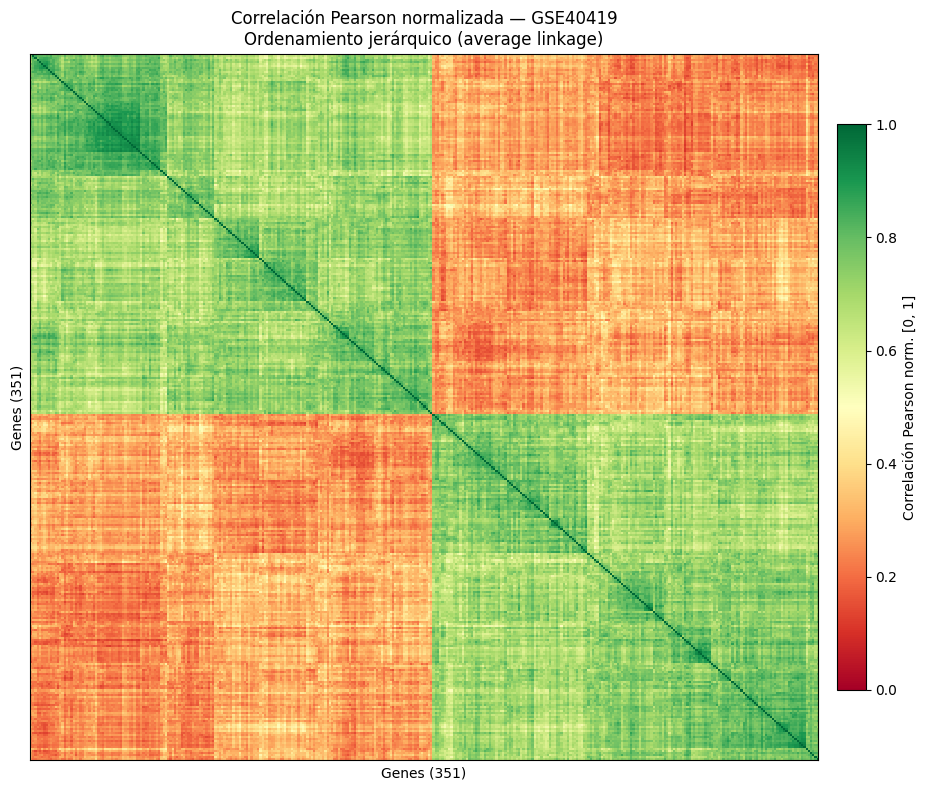

  Heatmap guardado en: C:\Users\benja\Desktop\workspace\Thesis\Datasets\Gene_Expression_reduced\GSE40419_heatmap_corr_pearson_norm.png

  GSE50760  [Pearson]
  Genes              : 365
  Forma matriz       : (365, 365)
  Orig. rango        : [-0.8910,  1.0000]
  Norm. media (tri.) : 0.5056
  Norm. std  (tri.)  : 0.2434
  CSV guardado en    : C:\Users\benja\Desktop\workspace\Thesis\Datasets\Gene_Expression_reduced\GSE50760_corr_pearson_norm.csv


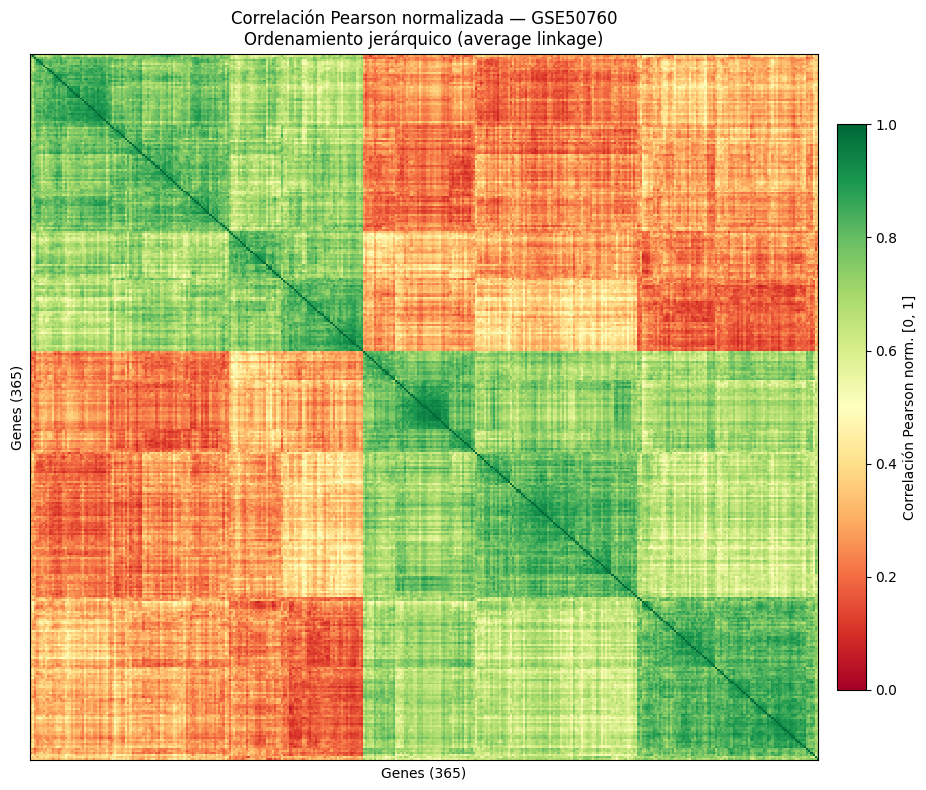

  Heatmap guardado en: C:\Users\benja\Desktop\workspace\Thesis\Datasets\Gene_Expression_reduced\GSE50760_heatmap_corr_pearson_norm.png

  GSE60052  [Pearson]
  Genes              : 563
  Forma matriz       : (563, 563)
  Orig. rango        : [-0.6814,  1.0000]
  Norm. media (tri.) : 0.5351
  Norm. std  (tri.)  : 0.1347
  CSV guardado en    : C:\Users\benja\Desktop\workspace\Thesis\Datasets\Gene_Expression_reduced\GSE60052_corr_pearson_norm.csv


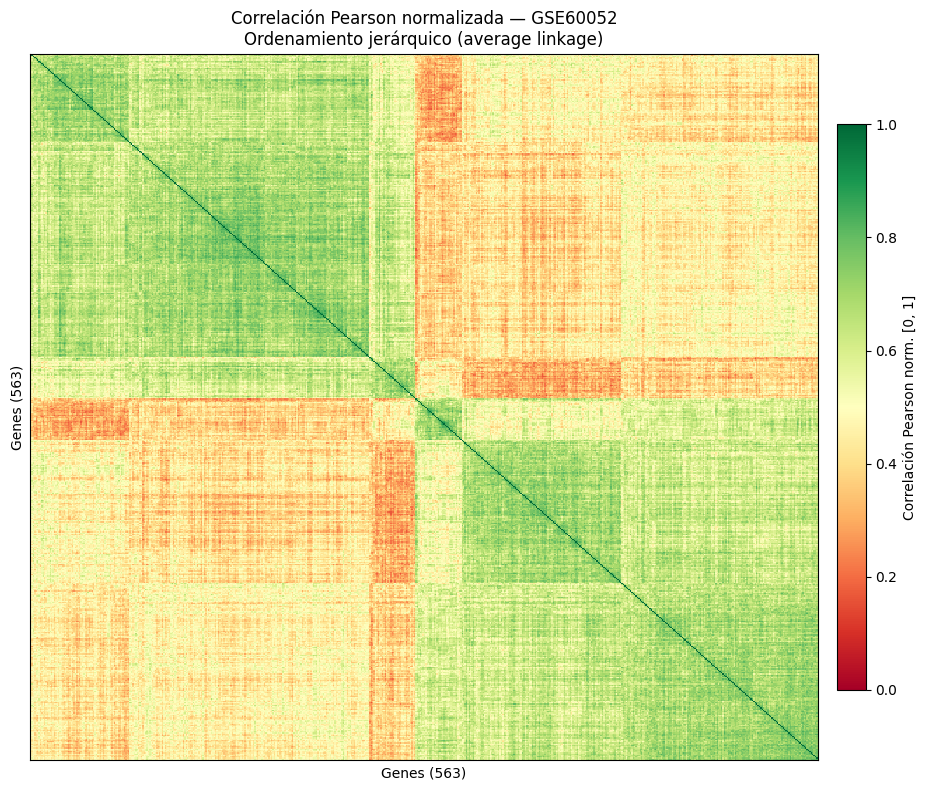

  Heatmap guardado en: C:\Users\benja\Desktop\workspace\Thesis\Datasets\Gene_Expression_reduced\GSE60052_heatmap_corr_pearson_norm.png

  GSE69240  [Pearson]
  Genes              : 957
  Forma matriz       : (957, 957)
  Orig. rango        : [-0.9110,  1.0000]
  Norm. media (tri.) : 0.5110
  Norm. std  (tri.)  : 0.2171
  CSV guardado en    : C:\Users\benja\Desktop\workspace\Thesis\Datasets\Gene_Expression_reduced\GSE69240_corr_pearson_norm.csv


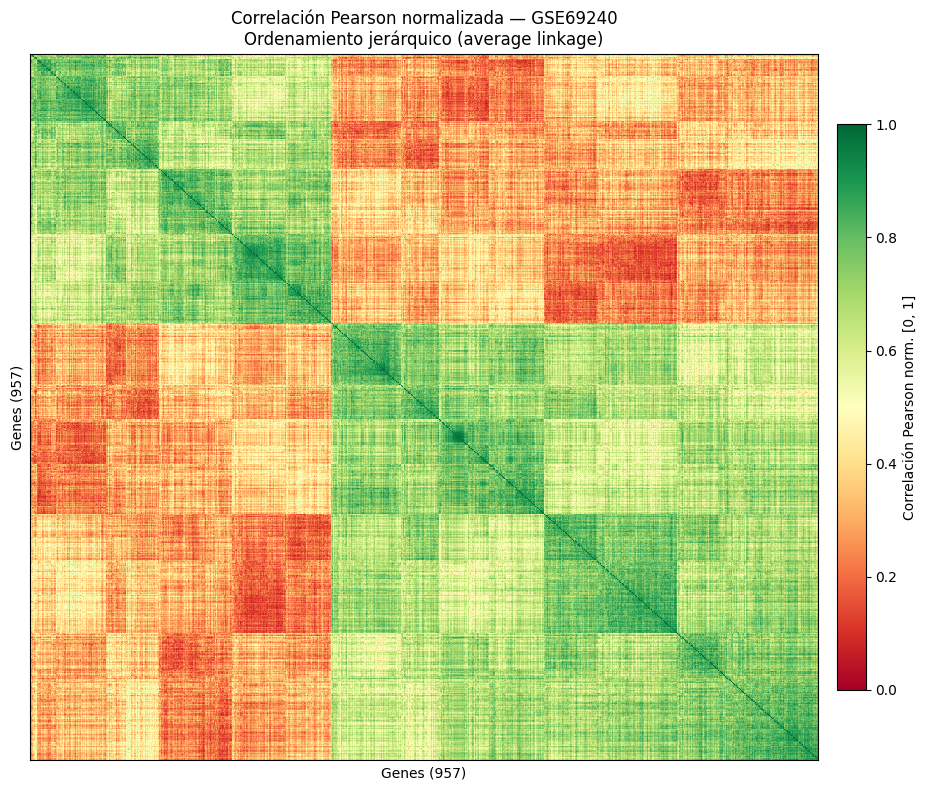

  Heatmap guardado en: C:\Users\benja\Desktop\workspace\Thesis\Datasets\Gene_Expression_reduced\GSE69240_heatmap_corr_pearson_norm.png

  GSE71651  [Pearson]
  Genes              : 87
  Forma matriz       : (87, 87)
  Orig. rango        : [-0.7990,  1.0000]
  Norm. media (tri.) : 0.5164
  Norm. std  (tri.)  : 0.2330
  CSV guardado en    : C:\Users\benja\Desktop\workspace\Thesis\Datasets\Gene_Expression_reduced\GSE71651_corr_pearson_norm.csv


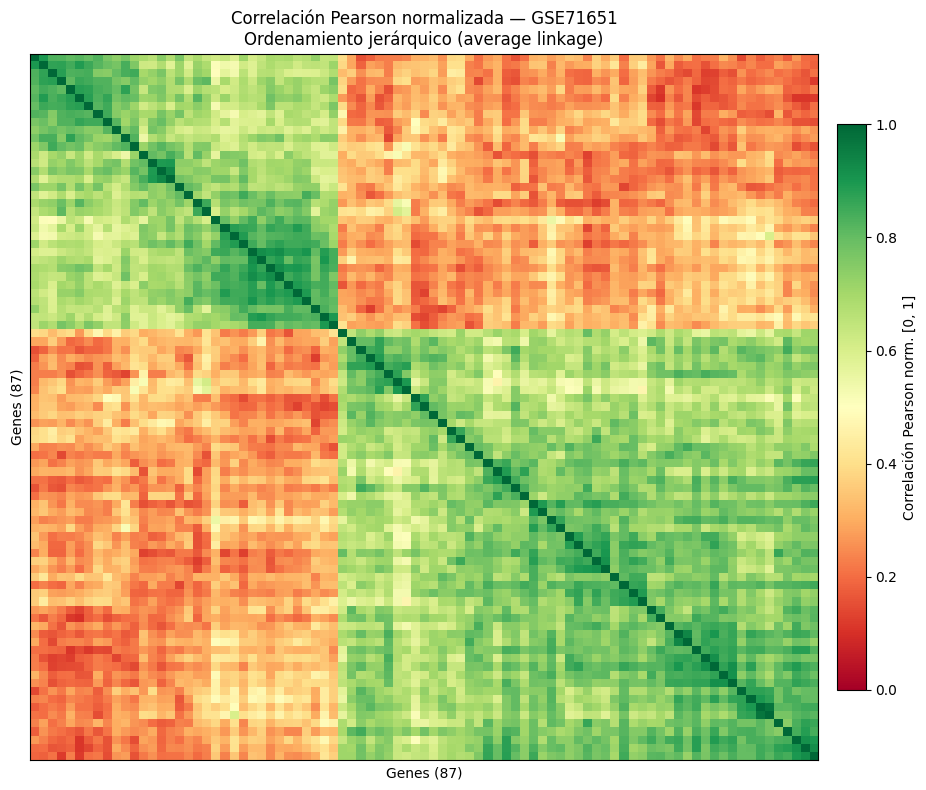

  Heatmap guardado en: C:\Users\benja\Desktop\workspace\Thesis\Datasets\Gene_Expression_reduced\GSE71651_heatmap_corr_pearson_norm.png

  ARCHIVOS GENERADOS

GSE40419  (351 genes)
  CSV : GSE40419_corr_pearson_norm.csv
  PNG : GSE40419_heatmap_corr_pearson_norm.png

GSE50760  (365 genes)
  CSV : GSE50760_corr_pearson_norm.csv
  PNG : GSE50760_heatmap_corr_pearson_norm.png

GSE60052  (563 genes)
  CSV : GSE60052_corr_pearson_norm.csv
  PNG : GSE60052_heatmap_corr_pearson_norm.png

GSE69240  (957 genes)
  CSV : GSE69240_corr_pearson_norm.csv
  PNG : GSE69240_heatmap_corr_pearson_norm.png

GSE71651  (87 genes)
  CSV : GSE71651_corr_pearson_norm.csv
  PNG : GSE71651_heatmap_corr_pearson_norm.png


In [7]:
def calcular_y_guardar_correlacion(nombre, datos, metodo='pearson'):
    """
    Calcula matriz de correlación (Pearson o Spearman), normaliza a [0,1],
    guarda CSV y genera un heatmap global con clustering jerárquico.

    Parámetros
    ----------
    nombre  : str   — nombre del dataset
    datos   : dict  — entrada desde DATASETS_PCA
    metodo  : str   — 'pearson' | 'spearman'
    """
    dataX   = datos['dataX']
    genes   = datos['genes']

    # --------------------------------------------------------
    # PASO 1: Calcular correlación según método
    # --------------------------------------------------------
    if metodo == 'pearson':
        corr_matrix = np.corrcoef(dataX, rowvar=False)

    elif metodo == 'spearman':
        corr_matrix, _ = spearmanr(dataX)
        if np.isscalar(corr_matrix):
            corr_matrix = np.array([[1.0, corr_matrix],
                                    [corr_matrix, 1.0]])
    else:
        raise ValueError(f"Método no soportado: {metodo}. Usar 'pearson' o 'spearman'.")

    # Sanidad: simetría, diagonal y rango
    corr_matrix = (corr_matrix + corr_matrix.T) / 2
    np.fill_diagonal(corr_matrix, 1.0)
    corr_matrix = np.clip(corr_matrix, -1.0, 1.0)

    # --------------------------------------------------------
    # PASO 2: Normalizar [-1, 1] → [0, 1]
    # --------------------------------------------------------
    corr_norm = (corr_matrix + 1) / 2
    df_corr   = pd.DataFrame(corr_norm, index=genes, columns=genes)

    vals_tri = corr_norm[np.triu_indices_from(corr_norm, k=1)]
    print(f"\n{'='*55}")
    print(f"  {nombre}  [{metodo.capitalize()}]")
    print(f"{'='*55}")
    print(f"  Genes              : {len(genes):,}")
    print(f"  Forma matriz       : {df_corr.shape}")
    print(f"  Orig. rango        : [{corr_matrix.min():.4f},  {corr_matrix.max():.4f}]")
    print(f"  Norm. media (tri.) : {vals_tri.mean():.4f}")
    print(f"  Norm. std  (tri.)  : {vals_tri.std():.4f}")

    # --------------------------------------------------------
    # PASO 3: Ordenamiento jerárquico
    # --------------------------------------------------------
    dist_condensed = squareform(np.clip(1 - corr_norm, 0, None), checks=False)
    linkage_mat    = linkage(dist_condensed, method='average')
    orden_genes    = leaves_list(linkage_mat)
    corr_norm_ord  = corr_norm[np.ix_(orden_genes, orden_genes)]

    # --------------------------------------------------------
    # PASO 4: Guardar CSV
    # --------------------------------------------------------
    output_path = OUTPUT_DIR_PREFIX / f"{nombre}_corr_{metodo}_norm.csv"
    df_corr.to_csv(output_path)
    print(f"  CSV guardado en    : {output_path}")

    # --------------------------------------------------------
    # PASO 5: Heatmap global único
    # --------------------------------------------------------
    fig, ax = plt.subplots(figsize=(10, 8))

    im   = ax.imshow(
        corr_norm_ord,
        cmap='RdYlGn',
        vmin=0, vmax=1,
        aspect='auto',
        interpolation='none'
    )
    cbar = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
    cbar.set_label(f'Correlación {metodo.capitalize()} norm. [0, 1]', fontsize=10)

    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel(f'Genes ({len(genes):,})', fontsize=10)
    ax.set_ylabel(f'Genes ({len(genes):,})', fontsize=10)
    ax.set_title(
        f'Correlación {metodo.capitalize()} normalizada — {nombre}\n'
        f'Ordenamiento jerárquico (average linkage)',
        fontsize=12
    )
    plt.tight_layout()

    fig_path = OUTPUT_DIR_PREFIX / f"{nombre}_heatmap_corr_{metodo}_norm.png"
    plt.savefig(fig_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"  Heatmap guardado en: {fig_path}")

    return df_corr, orden_genes


# ============================================================
# EJECUCIÓN
# ============================================================
RESULTADOS_CORR = {}

for nombre, datos in DATASETS_PCA.items():
    df_corr, orden = calcular_y_guardar_correlacion(
        nombre, datos, metodo='pearson'
    )
    RESULTADOS_CORR[nombre] = {
        'pearson': {'matriz': df_corr, 'orden': orden}
    }

# ============================================================
# RESUMEN FINAL
# ============================================================
separador = '=' * 55
print(f"\n{separador}")
print("  ARCHIVOS GENERADOS")
print(separador)
for nombre in DATASETS_PCA:
    n_genes = DATASETS_PCA[nombre]['dataX'].shape[1]
    print(f"\n{nombre}  ({n_genes:,} genes)")
    print(f"  CSV : {nombre}_corr_pearson_norm.csv")
    print(f"  PNG : {nombre}_heatmap_corr_pearson_norm.png")